# Mini-projet: Classification de feuilles d'arbres

Ce notebook est concu pour:
- entrainer plusieurs architectures CNN,
- varier les couches et les hyperparametres,
- comparer les performances,
- produire des elements exploitables dans le compte-rendu.

> Objectif vise: precision de validation/test > 75%.

In [1]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [2]:
# ----------------------------
# Configuration generale
# ----------------------------
SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# IMPORTANT:
# DATA_DIR doit pointer vers un dossier avec structure:
# DATA_DIR/
#   classe_1/*.jpg
#   classe_2/*.jpg
#   ...
# Chaque sous-dossier = une classe

DATA_DIR = "./data_32_classes"

CANDIDATE_DIRS = []

np.random.seed(SEED)
tf.random.set_seed(SEED)

for c in CANDIDATE_DIRS:
    if DATA_DIR is None and Path(c).exists():
        DATA_DIR = c

print('DATA_DIR actuel =', DATA_DIR)
if DATA_DIR is None:
    print('-> Definis DATA_DIR manuellement avant de lancer les cellules suivantes.')

DATA_DIR actuel = ./data_32_classes


In [3]:
# ----------------------------
# Chargement des donnees
# ----------------------------
def make_datasets(data_dir, img_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        validation_split=0.2,
        subset='training',
        seed=seed,
        image_size=img_size,
        batch_size=batch_size,
        label_mode='int',
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        validation_split=0.2,
        subset='validation',
        seed=seed,
        image_size=img_size,
        batch_size=batch_size,
        label_mode='int',
    )

    class_names = train_ds.class_names

    # Sous-division validation -> validation + test (50/50)
    val_batches = tf.data.experimental.cardinality(val_ds).numpy()
    test_batches = max(1, val_batches // 2)

    test_ds = val_ds.take(test_batches)
    val_ds_final = val_ds.skip(test_batches)

    train_ds = train_ds.cache().shuffle(1000, seed=seed).prefetch(buffer_size=AUTOTUNE)
    val_ds_final = val_ds_final.cache().prefetch(buffer_size=AUTOTUNE)
    test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

    return train_ds, val_ds_final, test_ds, class_names

if DATA_DIR is not None:
    train_ds, val_ds, test_ds, class_names = make_datasets(DATA_DIR)
    num_classes = len(class_names)
    print('Classes:', class_names)
    print('Nombre de classes:', num_classes)
else:
    print('DATA_DIR non defini.')

Found 4955 files belonging to 32 classes.
Using 3964 files for training.
Found 4955 files belonging to 32 classes.
Using 991 files for validation.
Classes: ['ashanti blood', 'barbados cherry', 'beaumier du perou', 'betel', 'bitter orange', 'caricature plant', 'chinese guava', 'chocolate tree', 'chrysanthemum', 'coeur demoiselle', 'coffee', 'croton', 'duranta gold', 'eggplant', 'ficus', 'fruitcitere', 'geranium', 'guava', 'hibiscus', 'jackfruit', 'ketembilla', 'lychee', 'mulberry leaf', 'papaya', 'pimento', 'pomme jacquot', 'rose', 'star apple', 'sweet olive', 'sweet potato', 'thevetia', 'vieux garcon']
Nombre de classes: 32


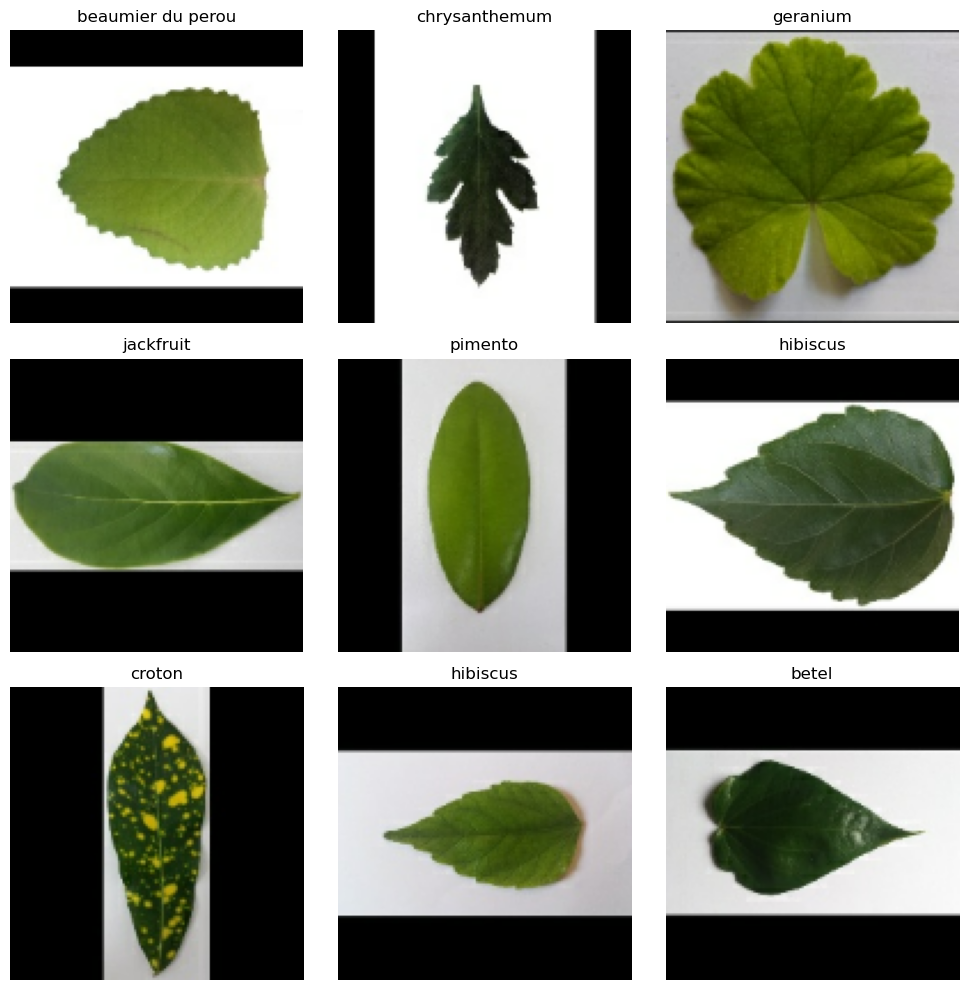

In [4]:
# Visualisation rapide d'un batch
if DATA_DIR is not None:
    plt.figure(figsize=(10, 10))
    for images, labels in train_ds.take(1):
        for i in range(min(9, len(images))):
            ax = plt.subplot(3, 3, i + 1)
            plt.imshow(images[i].numpy().astype('uint8'))
            plt.title(class_names[labels[i]])
            plt.axis('off')
    plt.tight_layout()
    plt.show()

In [5]:
# ----------------------------
# Architectures (variation couches)
# ----------------------------
def build_model(variant='A', num_classes=4, input_shape=(128, 128, 3), dropout=0.3):
    data_aug = keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
    ], name='augmentation')

    inputs = keras.Input(shape=input_shape)
    x = data_aug(inputs)
    x = layers.Rescaling(1.0 / 255)(x)

    if variant == 'A':
        # 2 blocs Conv
        x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)

    elif variant == 'B':
        # 3 blocs Conv
        x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)

    elif variant == 'C':
        # 3 blocs Conv + Dropout
        x = layers.Conv2D(32, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(128, 3, activation='relu', padding='same')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(dropout)(x)

    else:
        raise ValueError('variant doit etre A, B ou C')

    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    if variant == 'C':
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return keras.Model(inputs, outputs, name=f'model_{variant}')

In [6]:
# ----------------------------
# Entrainement + comparaison (variation parametres)
# ----------------------------
EXPERIMENTS = [
    # Étude du nombre d'epochs avec une architecture simple
    {'name': 'P1_ep3_A_adam',  'variant': 'A', 'optimizer': 'adam', 'lr': 1e-3, 'batch_size': 32, 'epochs': 3,  'dropout': 0.0},
    {'name': 'P1_ep5_A_adam',  'variant': 'A', 'optimizer': 'adam', 'lr': 1e-3, 'batch_size': 32, 'epochs': 5,  'dropout': 0.0},
    {'name': 'P1_ep10_A_adam', 'variant': 'A', 'optimizer': 'adam', 'lr': 1e-3, 'batch_size': 32, 'epochs': 10, 'dropout': 0.0},

    # Étude de la profondeur du réseau
    {'name': 'P1_2blocs_A_adam', 'variant': 'A', 'optimizer': 'adam', 'lr': 1e-3, 'batch_size': 32, 'epochs': 5, 'dropout': 0.0},
    {'name': 'P1_3blocs_B_adam', 'variant': 'B', 'optimizer': 'adam', 'lr': 1e-3, 'batch_size': 32, 'epochs': 5, 'dropout': 0.0},

    # Étude du dropout
    {'name': 'P1_3blocs_C_dropout03', 'variant': 'C', 'optimizer': 'adam', 'lr': 1e-3, 'batch_size': 32, 'epochs': 5, 'dropout': 0.3},

    # Étude de l'optimiseur
    {'name': 'P1_A_rmsprop', 'variant': 'A', 'optimizer': 'rmsprop', 'lr': 1e-3, 'batch_size': 32, 'epochs': 5, 'dropout': 0.0},
]


def get_optimizer(name, lr):
    if name.lower() == 'adam':
        return keras.optimizers.Adam(learning_rate=lr)
    if name.lower() == 'rmsprop':
        return keras.optimizers.RMSprop(learning_rate=lr)
    raise ValueError(f'Optimiseur inconnu: {name}')


def train_one_experiment(exp, data_dir):
    train_ds_local, val_ds_local, test_ds_local, class_names_local = make_datasets(
        data_dir,
        img_size=IMG_SIZE,
        batch_size=exp['batch_size'],
        seed=SEED,
    )

    model = build_model(
        variant=exp['variant'],
        num_classes=len(class_names_local),
        input_shape=(*IMG_SIZE, 3),
        dropout=exp['dropout'],
    )

    optimizer = get_optimizer(exp['optimizer'], exp['lr'])
    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )

    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
    ]

    history = model.fit(
        train_ds_local,
        validation_data=val_ds_local,
        epochs=exp['epochs'],
        callbacks=callbacks,
        verbose=1,
    )

    test_loss, test_acc = model.evaluate(test_ds_local, verbose=0)

    best_val_acc = float(np.max(history.history['val_accuracy']))
    best_train_acc = float(np.max(history.history['accuracy']))

    result = {
        'name': exp['name'],
        'variant': exp['variant'],
        'optimizer': exp['optimizer'],
        'lr': exp['lr'],
        'batch_size': exp['batch_size'],
        'epochs_target': exp['epochs'],
        'epochs_ran': len(history.history['loss']),
        'best_train_acc': best_train_acc,
        'best_val_acc': best_val_acc,
        'test_acc': float(test_acc),
        'test_loss': float(test_loss),
    }

    return model, history, result, class_names_local, test_ds_local


all_results = []
all_histories = {}
all_models = {}

if DATA_DIR is not None:
    for exp in EXPERIMENTS:
        print('\n' + '=' * 80)
        print('Lancement:', exp['name'])
        model, history, result, class_names, test_ds = train_one_experiment(exp, DATA_DIR)
        all_results.append(result)
        all_histories[exp['name']] = history.history
        all_models[exp['name']] = model

    results_df = pd.DataFrame(all_results).sort_values(by='best_val_acc', ascending=False)
    display(results_df)

    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')
    csv_name = f'resultats_cnn_{timestamp}.csv'
    json_name = f'resultats_cnn_{timestamp}.json'
    hist_name = f'historiques_cnn_{timestamp}.json'

    results_df.to_csv(csv_name, index=False)
    with open(json_name, 'w', encoding='utf-8') as f:
        json.dump(all_results, f, indent=2)
    with open(hist_name, 'w', encoding='utf-8') as f:
        json.dump(all_histories, f, indent=2)

    print(f'Fichiers sauves: {csv_name}, {json_name}, {hist_name}')
else:
    print('Definis DATA_DIR avant execution.')


Lancement: P1_ep3_A_adam
Found 4955 files belonging to 32 classes.
Using 3964 files for training.
Found 4955 files belonging to 32 classes.
Using 991 files for validation.
Epoch 1/3
124/124 ━━━━━━━━━━━━━━━━━━━━ 15s 106ms/step - accuracy: 0.1393 - loss: 3.1818 - val_accuracy: 0.3620 - val_loss: 2.2746
Epoch 2/3
124/124 ━━━━━━━━━━━━━━━━━━━━ 12s 100ms/step - accuracy: 0.4281 - loss: 1.9139 - val_accuracy: 0.4521 - val_loss: 1.6513
Epoch 3/3
124/124 ━━━━━━━━━━━━━━━━━━━━ 12s 95ms/step - accuracy: 0.5802 - loss: 1.3468 - val_accuracy: 0.6223 - val_loss: 1.1453

Lancement: P1_ep5_A_adam
Found 4955 files belonging to 32 classes.
Using 3964 files for training.
Found 4955 files belonging to 32 classes.
Using 991 files for validation.
Epoch 1/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 15s 102ms/step - accuracy: 0.1097 - loss: 3.2926 - val_accuracy: 0.2211 - val_loss: 2.6752
Epoch 2/5
124/124 ━━━━━━━━━━━━━━━━━━━━ 13s 107ms/step - accuracy: 0.3623 - loss: 2.1443 - val_accuracy: 0.4814 - val_loss: 1.7014
Epoch

,name,variant,optimizer,lr,batch_size,epochs_target,epochs_ran,best_train_acc,best_val_acc,test_acc,test_loss
2,P1_ep10_A_adam,A,adam,0.001,32,10,10,0.855701,0.841487,0.825000,0.500175
5,P1_3blocs_C_dropout03,C,adam,0.001,32,5,5,0.664985,0.800391,0.760417,0.760352
3,P1_2blocs_A_adam,A,adam,0.001,32,5,5,0.759586,0.720157,0.741667,0.743222
6,P1_A_rmsprop,A,rmsprop,0.001,32,5,5,0.664985,0.704501,0.727083,0.837681
1,P1_ep5_A_adam,A,adam,0.001,32,5,5,0.712412,0.692759,0.693750,0.969352
4,P1_3blocs_B_adam,B,adam,0.001,32,5,5,0.727800,0.673190,0.675000,1.053200
0,P1_ep3_A_adam,A,adam,0.001,32,3,3,0.580222,0.622309,0.662500,1.040066


Fichiers sauves: resultats_cnn_20260507_234315.csv, resultats_cnn_20260507_234315.json, historiques_cnn_20260507_234315.json


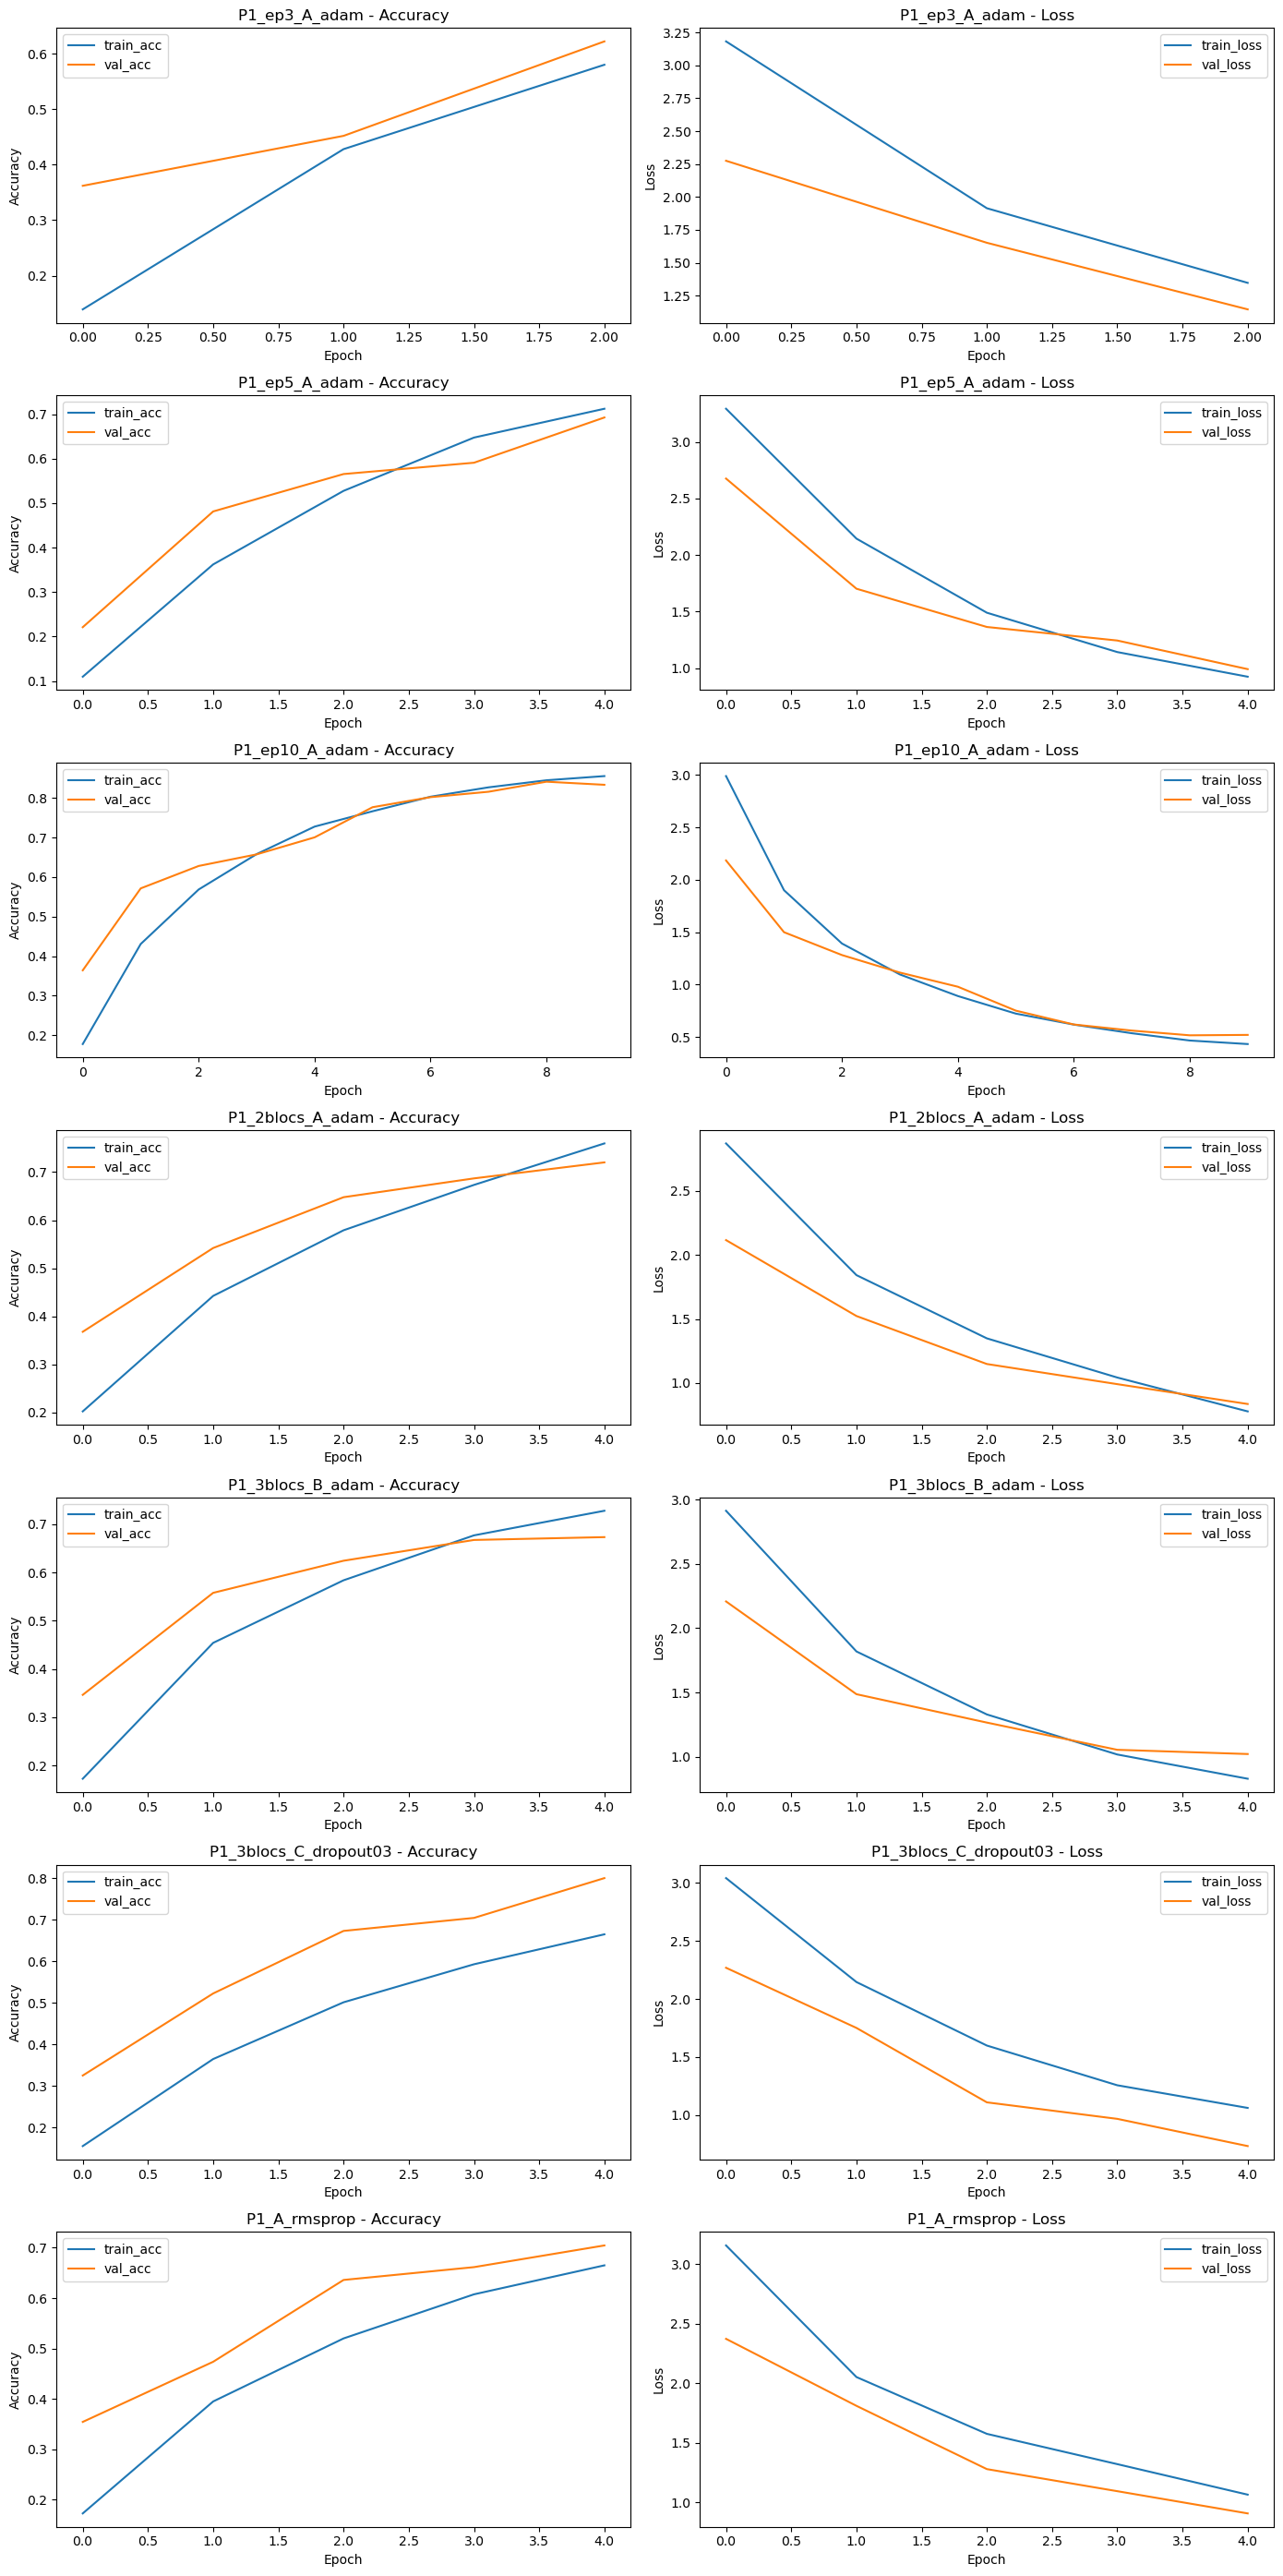

In [7]:
# Courbes d'apprentissage des experiences
if DATA_DIR is not None and len(all_histories) > 0:
    n = len(all_histories)
    plt.figure(figsize=(14, 4 * n))

    for i, (name, hist) in enumerate(all_histories.items(), start=1):
        plt.subplot(n, 2, 2 * i - 1)
        plt.plot(hist['accuracy'], label='train_acc')
        plt.plot(hist['val_accuracy'], label='val_acc')
        plt.title(f'{name} - Accuracy')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()

        plt.subplot(n, 2, 2 * i)
        plt.plot(hist['loss'], label='train_loss')
        plt.plot(hist['val_loss'], label='val_loss')
        plt.title(f'{name} - Loss')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()

    plt.tight_layout()
    plt.show()

Found 4955 files belonging to 32 classes.
Using 3964 files for training.
Found 4955 files belonging to 32 classes.
Using 991 files for validation.


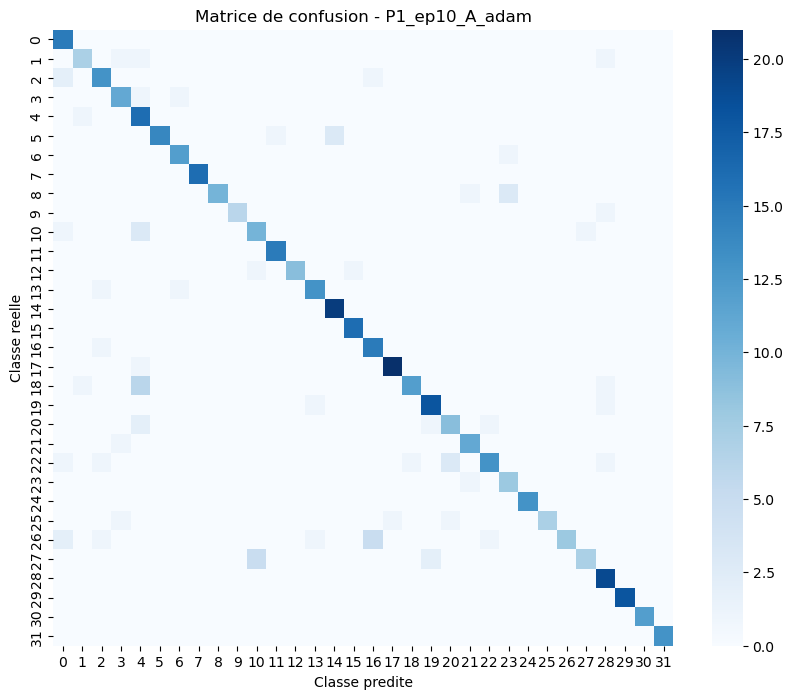

Meilleure experience: P1_ep10_A_adam
                   precision    recall  f1-score   support

    ashanti blood     0.7143    1.0000    0.8333        15
  barbados cherry     0.7778    0.7000    0.7368        10
beaumier du perou     0.7647    0.8125    0.7879        16
            betel     0.7857    0.8462    0.8148        13
    bitter orange     0.5333    0.9412    0.6809        17
 caricature plant     1.0000    0.7778    0.8750        18
    chinese guava     0.8571    0.9231    0.8889        13
   chocolate tree     1.0000    1.0000    1.0000        16
    chrysanthemum     1.0000    0.7143    0.8333        14
 coeur demoiselle     1.0000    0.8571    0.9231         7
           coffee     0.6250    0.6667    0.6452        15
           croton     0.9375    1.0000    0.9677        15
     duranta gold     1.0000    0.8182    0.9000        11
         eggplant     0.8667    0.8667    0.8667        15
            ficus     0.8696    1.0000    0.9302        20
      fruitcitere 

In [8]:
# Matrice de confusion + classification report pour le meilleur modele
if DATA_DIR is not None and len(all_results) > 0:
    best_exp_name = pd.DataFrame(all_results).sort_values('best_val_acc', ascending=False).iloc[0]['name']
    best_model = all_models[best_exp_name]

    # Reconstruit un test_ds avec le meme batch_size que l'experience gagnante
    best_exp = next(x for x in EXPERIMENTS if x['name'] == best_exp_name)
    _, _, best_test_ds, best_class_names = make_datasets(DATA_DIR, batch_size=best_exp['batch_size'])

    y_true = []
    y_pred = []

    for images, labels in best_test_ds:
        preds = best_model.predict(images, verbose=0)
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(np.argmax(preds, axis=1).tolist())

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, cmap='Blues')
    plt.title(f'Matrice de confusion - {best_exp_name}')
    plt.xlabel('Classe predite')
    plt.ylabel('Classe reelle')
    plt.show()

    print('Meilleure experience:', best_exp_name)
    print(classification_report(y_true, y_pred, target_names=best_class_names, digits=4))